# Figure list: which model → which HRF figures

Every HRF figure folder under `derivatives/eeg/HRF_surf` (plus the comparison PNGs in `code/eeg/modeling`) is listed in `REGISTRY`
with the model that produced it: HRF basis, design, noise model and the script that writes it.

* `summary()` — one row per model: number of group / per-subject figures, last update, forward model (Adot) of the figures.
* `list_figs(model, subject=...)` — table of the figure files of one model.
* `show(model, subject=..., contains=..., n=...)` — display the figures inline.
* `show_file(path)` — display one PNG.

**Adot column**: the image-space data switched to the new forward model (`flag = '_ADOT_updated'`, `Adot_v26.nc` of 2026-10-29)
for the rerun that started on 2026-11-06 09:46. Figures saved before that are from the old forward model.

In [2]:
import os, glob, datetime
import pandas as pd
from IPython.display import display, Image, Markdown

EEG_DER = '/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg'
HRF_SURF = os.path.join(EEG_DER, 'HRF_surf')
CODE_DIR = '/projectnb/nphfnirs/s/datasets/gradCPT_NN24/code/eeg/modeling'
SUBJECTS = ['sub-670', 'sub-695', 'sub-721', 'sub-723', 'sub-726', 'sub-730']
NEW_ADOT_SINCE = datetime.datetime(2026, 11, 6, 9, 46)   # start of the new-Adot rerun
pd.set_option('display.max_colwidth', 80); pd.set_option('display.max_rows', 200)

## Model registry
`group` / `subj` are folders relative to `HRF_surf` (`{sub}` is replaced by the subject); `None` = no such figures.
Families: **contEEG** = continuous Cz convolved with a B-spline HRF over delays; **GK** = Gaussian-kernel event regressors
(mnt-correct onsets); **Bayes** = Bayesian single-parcel Gaussian-kernel model; **cmp** = figures comparing several models.

In [3]:
R = []
def reg(model, family, hrf_basis, design, noise_model, script, group=None, subj=None, extra=None):
    R.append(dict(model=model, family=family, hrf_basis=hrf_basis, design=design, noise_model=noise_model,
                  script=script, group=group, subj=subj, extra=extra))

BS = 'B-spline (20), delays -2..18 s'
BS15 = 'B-spline, delays 0..15 s'
GK = 'Gaussian kernels (20), -2..18 s'

# ---- continuous EEG (Cz) over the entire run ----
reg('contEEG_1stage', 'contEEG', BS15, 'Cz entire run', 'AR-IRLS (1-stage)', 'vis_hrf_cont_EEG_cz.py',
    group='cont_EEG_cz', subj='{sub}/cont_EEG_cz')
reg('contEEG_bspline_first', 'contEEG', BS15, 'Cz entire run, B-spline before resampling', 'AR-IRLS', 'vis_hrf_cont_EEG_cz.py',
    group='cont_EEG_cz_bspline_first', subj='{sub}/cont_EEG_cz_bspline_first')
reg('contEEG_3stage', 'contEEG', BS, 'Cz entire run (drift + GSR OLS first)', 'AR-IRLS (3-stage)',
    'run_model_cont_EEG_fNIRS.py → vis_hrf_cont_EEG_cz.py', group='cont_EEG_cz_3-stage', subj='{sub}/cont_EEG_cz_3-stage')
reg('contEEG_3stage_fixAR-IRLS', 'contEEG', BS, 'Cz entire run', 'fixAR-IRLS', 'run_model_cont_EEG_fNIRS_fixAR-IRLS.py → vis_hrf_cont_EEG_cz.py',
    group='cont_EEG_cz_3-stage_fixAR-IRLS', subj='{sub}/cont_EEG_cz_3-stage_fixAR-IRLS')
reg('contEEG_3stage_iRRR', 'contEEG', BS, 'Cz entire run', 'iRRR (no AR)', 'run_model_cont_EEG_fNIRS_iRRR.py / _iRRR_group.py',
    group='cont_EEG_cz_3-stage_iRRR', subj='{sub}/cont_EEG_cz_3-stage_iRRR')
reg('contEEG_3stage_AR-iRRR', 'contEEG', BS, 'Cz entire run', 'AR-iRRR', 'run_model_cont_EEG_fNIRS_AR-iRRR.py',
    subj='{sub}/cont_EEG_cz_3-stage_iRRR_AR_Hp')
reg('contEEG_3stage_AR-iRRR_noScale', 'contEEG', BS, 'Cz entire run, Y not scaled', 'AR-iRRR', 'run_model_cont_EEG_fNIRS_AR-iRRR.py',
    subj='{sub}/cont_EEG_cz_3-stage_iRRR_AR_noScale_Hp')
reg('contEEG_3stage_AR-iRRR_network', 'contEEG', BS, 'Cz entire run, iRRR per network', 'AR-iRRR',
    'run_model_cont_EEG_fNIRS_AR-iRRR_network-based.py', subj='{sub}/cont_EEG_cz_3-stage_AR-iRRR-network_Hp')
reg('contEEG_add_VTC', 'contEEG', BS15, 'Cz entire run + VTC', 'AR-IRLS (1-stage)', 'run_model_cont_EEG_fNIRS_add_VTC.py (old)',
    group='cont_EEG_cz_add_VTC')
reg('contEEG_add_VTC_3stage', 'contEEG', BS, 'Cz entire run + VTC', 'AR-IRLS (3-stage)', 'run_model_cont_EEG_fNIRS_add_VTC.py',
    group='cont_EEG_cz_add_VTC_3-stage', subj='{sub}/cont_EEG_cz_add_VTC_3-stage')
reg('contEEG_preWhiten_train-gradcpt1', 'contEEG', BS, 'Cz, trained on gradcpt1, tested on runs 2-3', 'fixAR-IRLS vs AR-iRRR',
    'cmp_fixAR-IRLS_AR-iRRR_single-subj_single-run.py', subj='{sub}/cont_EEG_cz_preWhiten_train-gradcpt1')
reg('contEEG_postWhiten_train-allRuns', 'contEEG', BS, 'Cz, all runs', 'fixAR-IRLS vs AR-iRRR',
    'cmp_fixAR-IRLS_AR-iRRR_single-subj_all-runs.py', subj='{sub}/cont_EEG_cz_postWhiten_train-allRuns')

# ---- continuous EEG (Cz) masked to trials ----
reg('contEEG_city_mnt (old)', 'contEEG', BS15, 'Cz masked to city / mnt trials', 'AR-IRLS', 'vis_hrf_cont_EEG_city_mnt.py',
    group='cont_EEG_city_mnt_cz', subj='{sub}/cont_EEG_city_mnt_cz')
reg('contEEG_mnt_correct_incorrect', 'contEEG', BS, 'Cz masked to mnt-correct / mnt-incorrect trials', 'AR-iRRR',
    'run_model_cont_EEG_city_mnt.py', group='cont_EEG_cz_mnt_correct_incorrect_pre2post18',
    subj='{sub}/cont_EEG_cz_mnt_correct_incorrect_pre2post18_iRRR_AR_Hp0.01')
reg('contEEG_mnt_correct_incorrect_bl', 'contEEG', BS, 'as above, Cz baseline (-0.2-0 s) removed per trial', 'AR-iRRR',
    'run_model_cont_EEG_city_mnt.py', subj='{sub}/cont_EEG_cz_mnt_correct_incorrect_pre2post18_bl0.2-0_iRRR_AR_Hp0.01')
reg('contEEG_mnt-correct_network', 'contEEG', BS, 'Cz masked to mnt-correct, iRRR per network', 'AR-iRRR / fixAR-IRLS',
    'run_model_cont_EEG_mnt-correct_network-based.py', group='cont_EEG_cz_mnt-correct_pre2post18_3-stage',
    subj='{sub}/cont_EEG_cz_mnt-correct_pre2post18_3-stage_AR-iRRR-network_Hp')

# ---- Gaussian-kernel event models ----
reg('GK_onParcel_onlyStim', 'GK', GK, 'mnt-correct + mnt-incorrect onsets, amplitude 1', 'AR-IRLS',
    'run_model_EEG_inform_parcel_based.py (old version)', group='event-based_onParcel_onlyStim',
    subj='{sub}/event-based_onParcel_onlyStim')
reg('GK_3stage', 'GK', GK, 'mnt-correct onsets', 'AR-IRLS (3-stage)', 'summary notebook', group='mnt-correct_gauss_3-stage')
reg('GK_AR-iRRR_network', 'GK', GK, 'mnt-correct onsets, iRRR per network', 'AR-iRRR',
    'run_model_gaussian-kernel_mnt-correct_network-based.py', subj='{sub}/mnt-correct_gauss_3-stage_AR-iRRR-network_Hp')
reg('GK_cmp_AR-IRLS_fixAR-IRLS', 'GK', GK, 'mnt-correct onsets', 'AR-IRLS vs fixAR-IRLS', 'cmp_AR-IRLS_fixAR-IRLS_single-subj.py',
    subj='{sub}/mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS')
reg('GK_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR', 'GK', GK, 'mnt-correct onsets', 'AR-IRLS vs fixAR-IRLS vs AR-iRRR',
    'cmp_AR-IRLS_fixAR-IRLS_AR-iRRR.py', group='mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR',
    subj='{sub}/mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR')
reg('GK_cmp_..._rank_sweep', 'GK', GK, 'mnt-correct onsets, iRRR rank sweep', 'AR-iRRR', 'cmp_AR-IRLS_fixAR-IRLS_AR-iRRR.py',
    group='mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR_rank_sweep')
reg('GK_cmp_..._train-gradcpt1', 'GK', GK, 'mnt-correct onsets, trained on gradcpt1', 'AR-IRLS vs fixAR-IRLS vs AR-iRRR',
    'cmp_AR-IRLS_fixAR-IRLS_AR-iRRR.py', group='mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR_train-gradcpt1',
    subj='{sub}/mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR_train-gradcpt1')
reg('GK_preWhiten_train-gradcpt1', 'GK', GK, 'mnt-correct onsets, trained on gradcpt1', 'fixAR-IRLS vs AR-iRRR',
    'cmp_fixAR-IRLS_AR-iRRR_single-subj_single-run.py', subj='{sub}/mnt-correct_gauss_preWhiten_train-gradcpt1')
reg('GK_postWhiten_train-allRuns', 'GK', GK, 'mnt-correct onsets, all runs', 'fixAR-IRLS vs AR-iRRR',
    'cmp_fixAR-IRLS_AR-iRRR_single-subj_all-runs.py', subj='{sub}/mnt-correct_gauss_postWhiten_train-allRuns')

# ---- Bayesian ----
reg('Bayes_GK', 'Bayes', GK, 'mnt-correct onsets, single parcel, gradcpt1', 'Bayesian AR (smoothness prior)',
    'Bayesian model/run_Bayes_image-space_gaussian-kernel_mnt-correct.py',
    subj='{sub}/Bayes-HRF-AR_mnt-correct_gauss_1-stage_gradcpt1_Hp')
reg('Bayes_GK_noSmooth', 'Bayes', GK, 'as above, no smoothness prior', 'Bayesian AR',
    'Bayesian model/run_Bayes_image-space_gaussian-kernel_mnt-correct.py',
    subj='{sub}/Bayes-HRF-AR_mnt-correct_gauss_1-stage_gradcpt1_Hp_noSmooth')

# ---- comparisons across models ----
reg('cmp_contEEG_models', 'cmp', BS, 'contEEG: AR-IRLS / fixAR-IRLS / iRRR / AR-iRRR', 'several', 'cmp_model_hrf_r2.py',
    group='cont_EEG_cz_3-stage_model_cmp')
reg('cmp_contEEG_mnt_models', 'cmp', BS, 'contEEG masked mnt trials', 'several', 'cmp_model_hrf_r2.py',
    group='cont_EEG_cz_mnt_correct_incorrect_model_cmp')
reg('cmp_contEEG_AR-iRRR_vs_fixAR-IRLS_network', 'cmp', BS, 'contEEG per network', 'AR-iRRR vs fixAR-IRLS',
    'summary notebook', group='cont_EEG_cz_3-stage_AR-iRRR_vs_fixAR-IRLS-network_Hp')
reg('cmp_fixAR-IRLS_AR-iRRR_train-gradcpt1', 'cmp', 'B-spline + GK', 'contEEG and GK, train gradcpt1', 'fixAR-IRLS vs AR-iRRR',
    'cmp_fixAR-IRLS_AR-iRRR_single-subj_single-run.py', group='cmp_fixAR-IRLS_AR-iRRR_preWhiten_train-gradcpt1')
reg('cmp_fixAR-IRLS_AR-iRRR_single-subj', 'cmp', 'B-spline + GK', 'contEEG and GK', 'fixAR-IRLS vs AR-iRRR',
    'cmp_fixAR-IRLS_AR-iRRR_single-subj_*.py', group='cmp_fixAR-IRLS_AR-iRRR_single-subj')
reg('cmp_mnt-correct_4-design', 'cmp', 'B-spline + GK', 'GK vs EEG-informed GK vs contEEG designs', 'AR-IRLS',
    'summary notebook', group='mnt-correct_4-design_cmp')
reg('cmp_mnt-correct_4-script', 'cmp', 'B-spline + GK', 'mnt-correct HRF from 4 scripts', 'AR-IRLS / fixAR-IRLS / AR-iRRR',
    'summary notebook', group='mnt-correct_4-script_cmp')
reg('cmp_parcel_DorsAttnB_PostC_2_RH', 'cmp', 'B-spline + GK', 'one parcel: EEG-informed GK, contEEG mnt, contEEG run', 'AR-IRLS',
    'summary notebook', group='parcel_DorsAttnB_PostC_2_RH')
reg('cmp_Cedalion-pipe_My-pipe', 'cmp', GK, 'cedalion pipeline vs this pipeline', 'AR-IRLS', 'cmp_Cedalion-pipe_My-pipe.py',
    subj='{sub}/cmp_Cedalion-pipe_My-pipe')
reg('cmp_HRF_DM (onlyStim / onlyEEG / contEEG / Bayes)', 'cmp', 'B-spline + GK', 'sub-723, 2 parcels, mnt-correct', 'AR-IRLS + Bayes',
    'cmp_hrf_gaussian-kernel_vs_cont-EEG_mnt-correct.py', extra=os.path.join(EEG_DER, 'single_Subj_results', 'Compare_GK-onlyStim_GK-onlyEEG_Bayesian_ContEEG-mnt-correct',
                       'cmp_HRF_DM_{sub}_mnt-correct.png'))
reg('diag_contEEG_flat_hrf', 'cmp', BS, 'why the contEEG mnt-correct HRF is flat (sub-723)', 'AR-IRLS',
    'diag_contEEG_flat_hrf.py', extra=os.path.join(CODE_DIR, 'diag_contEEG_flat_hrf_{sub}*.png'))

# ---- parcel location maps (no HRF) ----
reg('parcel_locations', 'location', '-', 'surface maps of selected parcels', '-', 'cmp_*_single-subj*.py / vis_hrf_cont_EEG_cz.py',
    extra=os.path.join(HRF_SURF, '{sub}', 'surf_parcel_*.png'))

# ---- decompositions of HRFs ----
reg('SVD_components', 'decomp', BS, 'SVD of contEEG HRFs across parcels', '-', 'single_subj_HRF_analysis.py',
    subj='{sub}/SVD_components')
reg('ICA_components', 'decomp', BS, 'ICA of contEEG HRFs across parcels', '-', 'single_subj_HRF_analysis.py',
    subj='{sub}/ICA_components')
reg('iRRR_components', 'decomp', BS, 'iRRR components', '-', 'check_iRRR.py', subj='{sub}/iRRR_components')

REGISTRY = pd.DataFrame(R).set_index('model')
REGISTRY[['family', 'hrf_basis', 'design', 'noise_model', 'script']]

,family,hrf_basis,design,noise_model,script
model,,,,,
contEEG_1stage,contEEG,"B-spline, delays 0..15 s",Cz entire run,AR-IRLS (1-stage),vis_hrf_cont_EEG_cz.py
contEEG_bspline_first,contEEG,"B-spline, delays 0..15 s","Cz entire run, B-spline before resampling",AR-IRLS,vis_hrf_cont_EEG_cz.py
contEEG_3stage,contEEG,"B-spline (20), delays -2..18 s",Cz entire run (drift + GSR OLS first),AR-IRLS (3-stage),run_model_cont_EEG_fNIRS.py → vis_hrf_cont_EEG_cz.py
contEEG_3stage_fixAR-IRLS,contEEG,"B-spline (20), delays -2..18 s",Cz entire run,fixAR-IRLS,run_model_cont_EEG_fNIRS_fixAR-IRLS.py → vis_hrf_cont_EEG_cz.py
contEEG_3stage_iRRR,contEEG,"B-spline (20), delays -2..18 s",Cz entire run,iRRR (no AR),run_model_cont_EEG_fNIRS_iRRR.py / _iRRR_group.py
contEEG_3stage_AR-iRRR,contEEG,"B-spline (20), delays -2..18 s",Cz entire run,AR-iRRR,run_model_cont_EEG_fNIRS_AR-iRRR.py
contEEG_3stage_AR-iRRR_noScale,contEEG,"B-spline (20), delays -2..18 s","Cz entire run, Y not scaled",AR-iRRR,run_model_cont_EEG_fNIRS_AR-iRRR.py
contEEG_3stage_AR-iRRR_network,contEEG,"B-spline (20), delays -2..18 s","Cz entire run, iRRR per network",AR-iRRR,run_model_cont_EEG_fNIRS_AR-iRRR_network-based.py
contEEG_add_VTC,contEEG,"B-spline, delays 0..15 s",Cz entire run + VTC,AR-IRLS (1-stage),run_model_cont_EEG_fNIRS_add_VTC.py (old)


## Helpers

In [4]:
def _resolve(model):
    if model in REGISTRY.index:
        return model
    hits = [m for m in REGISTRY.index if model.lower() in m.lower()]
    if len(hits) == 1:
        return hits[0]
    raise KeyError(f"'{model}' matches {hits if hits else 'no model'}; see REGISTRY.index")

def _globs(model, subject):
    r = REGISTRY.loc[model]
    if r.extra:
        if subject == 'group':
            return [] if '{sub}' in r.extra else [r.extra]
        return [r.extra.format(sub=subject)] if '{sub}' in r.extra else []
    if subject == 'group':
        return [os.path.join(HRF_SURF, 'group', r.group, '**', '*.png')] if r.group else []
    return [os.path.join(HRF_SURF, r.subj.format(sub=subject), '**', '*.png')] if r.subj else []

def list_figs(model, subject='group', contains=None):
    # table of the PNGs of one model; subject = 'group' or 'sub-XXX'; contains = substring(s) of the file path
    model = _resolve(model)
    files = sorted({f for g in _globs(model, subject) for f in glob.glob(g, recursive=True)})
    if contains:
        keys = [contains] if isinstance(contains, str) else contains
        files = [f for f in files if all(k.lower() in f.lower() for k in keys)]
    rows = []
    for f in files:
        t = datetime.datetime.fromtimestamp(os.path.getmtime(f))
        rows.append(dict(file=os.path.relpath(f, HRF_SURF) if f.startswith(HRF_SURF) else f,
                         modified=t.strftime('%Y-%m-%d %H:%M'), adot='new' if t >= NEW_ADOT_SINCE else 'old', path=f))
    return pd.DataFrame(rows, columns=['file', 'modified', 'adot', 'path'])

def show(model, subject='group', contains=None, n=6, width=900):
    # display up to n figures of a model, e.g. show('contEEG_3stage', 'sub-723', contains='SomMotA')
    model = _resolve(model)
    r = REGISTRY.loc[model]
    df = list_figs(model, subject, contains)
    display(Markdown(f"### {model} — {subject}\n**HRF basis:** {r.hrf_basis} · **design:** {r.design} · "
                     f"**noise model:** {r.noise_model} · **script:** `{r.script}` · {len(df)} figure(s)"))
    if df.empty:
        print('No figures (try another subject, or check REGISTRY for which of group / subj exists).')
        return df
    for _, row in df.head(n).iterrows():
        display(Markdown(f"`{row.file}` · {row.modified} · **{row.adot} Adot**"))
        display(Image(filename=row.path, width=width))
    if len(df) > n:
        print(f'... {len(df) - n} more; use n= or contains= (list_figs() shows all names)')
    return None

def show_file(path, width=900):
    display(Markdown(f"`{path}`")); display(Image(filename=path, width=width))

def summary():
    rows = []
    for m, r in REGISTRY.iterrows():
        g = list_figs(m, 'group')
        s = pd.concat([list_figs(m, sub) for sub in SUBJECTS], ignore_index=True)
        allf = pd.concat([g, s], ignore_index=True).drop_duplicates('path')
        rows.append(dict(model=m, family=r.family, noise_model=r.noise_model,
                         n_group=len(g), n_subj=len(s),
                         subjects=','.join(sub[-3:] for sub in SUBJECTS if not list_figs(m, sub).empty) if not r.extra else '',
                         last_update=allf.modified.max() if len(allf) else '',
                         adot='/'.join(sorted(allf.adot.unique())) if len(allf) else ''))
    return pd.DataFrame(rows).set_index('model')

## Summary: figures per model

In [5]:
summary()

,family,noise_model,n_group,n_subj,subjects,last_update,adot
model,,,,,,,
contEEG_1stage,contEEG,AR-IRLS (1-stage),26,150,"670,695,721,723,726,730",2026-10-08 17:01,old
contEEG_bspline_first,contEEG,AR-IRLS,15,150,"670,695,721,723,726,730",2026-09-02 16:16,old
contEEG_3stage,contEEG,AR-IRLS (3-stage),15,150,"670,695,721,723,726,730",2026-09-14 16:34,old
contEEG_3stage_fixAR-IRLS,contEEG,fixAR-IRLS,15,150,"670,695,721,723,726,730",2026-10-08 17:01,old
contEEG_3stage_iRRR,contEEG,iRRR (no AR),10,42,"670,695,721,723,726,730",2026-11-06 10:17,new/old
contEEG_3stage_AR-iRRR,contEEG,AR-iRRR,0,42,"670,695,721,723,726,730",2026-11-06 10:09,new/old
contEEG_3stage_AR-iRRR_noScale,contEEG,AR-iRRR,0,42,"670,695,721,723,726,730",2026-10-09 14:41,old
contEEG_3stage_AR-iRRR_network,contEEG,AR-iRRR,0,102,"670,695,721,723,726,730",2026-11-06 10:16,new
contEEG_add_VTC,contEEG,AR-IRLS (1-stage),15,0,,2026-09-08 11:18,old


## Folders not in the registry
Any figure folder under `HRF_surf` that no registry entry covers (new script outputs show up here).

In [6]:
import re
known = set()
for _, r in REGISTRY.iterrows():
    if r.group: known.add(os.path.join('group', r.group))
    if r.subj: known.add(r.subj.format(sub='sub-XXX'))
known_files = {re.sub(r'sub-\d{3}', 'sub-XXX', f) for m in REGISTRY.index[REGISTRY.extra.notna()]
               for sub in ['group'] + SUBJECTS for f in list_figs(m, sub).path}
unlisted = sorted({os.path.dirname(rel) or '(HRF_surf root)'
                   for f in glob.glob(os.path.join(HRF_SURF, '**', '*.png'), recursive=True)
                   for rel in [re.sub(r'sub-\d{3}', 'sub-XXX', os.path.relpath(f, HRF_SURF))]
                   if not any(rel.startswith(k + os.sep) for k in known)
                   and re.sub(r'sub-\d{3}', 'sub-XXX', f) not in known_files})
unlisted   # HRF_surf root: all_parcels.png / dorsAttn_default_parcels.png (parcel maps, show_file() them)

['(HRF_surf root)']

## Examples
Change the model / subject / `contains` to browse. `list_figs(...)` first if you want the file names.

In [7]:
list_figs('contEEG_3stage_AR-iRRR_network', 'sub-723').head(20)

,file,modified,adot,path
0,sub-723/cont_EEG_cz_3-stage_AR-iRRR-network_Hp/sub-723_ContA_iRRR_lam1_vs_ra...,2026-11-06 10:13,new,/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/sub-723...
1,sub-723/cont_EEG_cz_3-stage_AR-iRRR-network_Hp/sub-723_ContB_iRRR_lam1_vs_ra...,2026-11-06 10:13,new,/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/sub-723...
2,sub-723/cont_EEG_cz_3-stage_AR-iRRR-network_Hp/sub-723_ContC_iRRR_lam1_vs_ra...,2026-11-06 10:13,new,/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/sub-723...
3,sub-723/cont_EEG_cz_3-stage_AR-iRRR-network_Hp/sub-723_DefaultA_iRRR_lam1_vs...,2026-11-06 10:13,new,/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/sub-723...
4,sub-723/cont_EEG_cz_3-stage_AR-iRRR-network_Hp/sub-723_DefaultB_iRRR_lam1_vs...,2026-11-06 10:13,new,/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/sub-723...
5,sub-723/cont_EEG_cz_3-stage_AR-iRRR-network_Hp/sub-723_DefaultC_iRRR_lam1_vs...,2026-11-06 10:13,new,/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/sub-723...
6,sub-723/cont_EEG_cz_3-stage_AR-iRRR-network_Hp/sub-723_DorsAttnA_iRRR_lam1_v...,2026-11-06 10:13,new,/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/sub-723...
7,sub-723/cont_EEG_cz_3-stage_AR-iRRR-network_Hp/sub-723_DorsAttnB_iRRR_lam1_v...,2026-11-06 10:13,new,/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/sub-723...
8,sub-723/cont_EEG_cz_3-stage_AR-iRRR-network_Hp/sub-723_LimbicA_iRRR_lam1_vs_...,2026-11-06 10:13,new,/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/sub-723...
9,sub-723/cont_EEG_cz_3-stage_AR-iRRR-network_Hp/sub-723_LimbicB_iRRR_lam1_vs_...,2026-11-06 10:13,new,/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/sub-723...


In [8]:
show('cmp_HRF_DM', 'sub-726')

### cmp_HRF_DM (onlyStim / onlyEEG / contEEG / Bayes) — sub-726
**HRF basis:** B-spline + GK · **design:** sub-723, 2 parcels, mnt-correct · **noise model:** AR-IRLS + Bayes · **script:** `cmp_hrf_gaussian-kernel_vs_cont-EEG_mnt-correct.py` · 0 figure(s)

No figures (try another subject, or check REGISTRY for which of group / subj exists).


,file,modified,adot,path


### contEEG_mnt-correct_network — sub-723
**HRF basis:** B-spline (20), delays -2..18 s · **design:** Cz masked to mnt-correct, iRRR per network · **noise model:** AR-iRRR / fixAR-IRLS · **script:** `run_model_cont_EEG_mnt-correct_network-based.py` · 17 figure(s)

`sub-723/cont_EEG_cz_mnt-correct_pre2post18_3-stage_AR-iRRR-network_Hp/sub-723_ContA_iRRR_lam1_vs_rank.png` · 2026-11-06 11:17 · **new Adot**

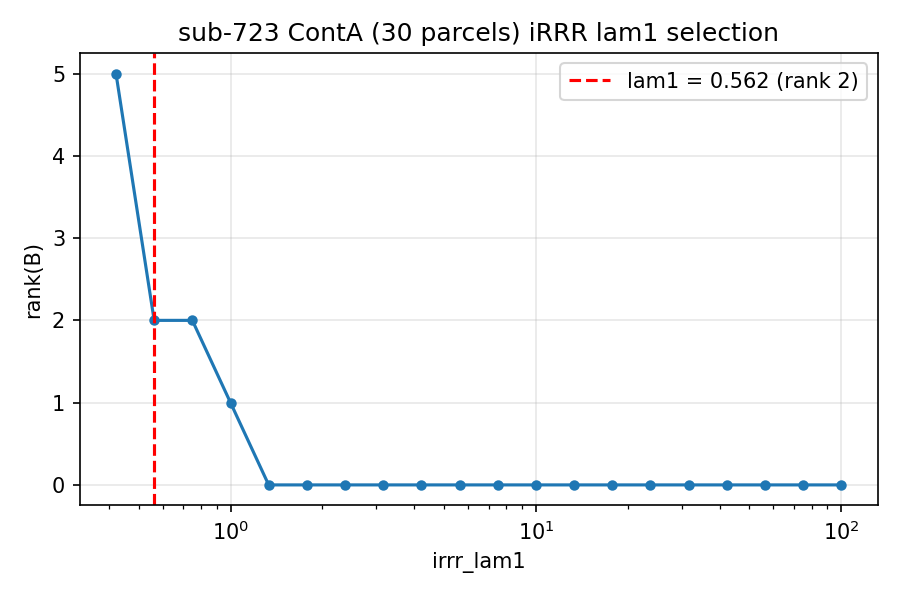

`sub-723/cont_EEG_cz_mnt-correct_pre2post18_3-stage_AR-iRRR-network_Hp/sub-723_ContB_iRRR_lam1_vs_rank.png` · 2026-11-06 11:18 · **new Adot**

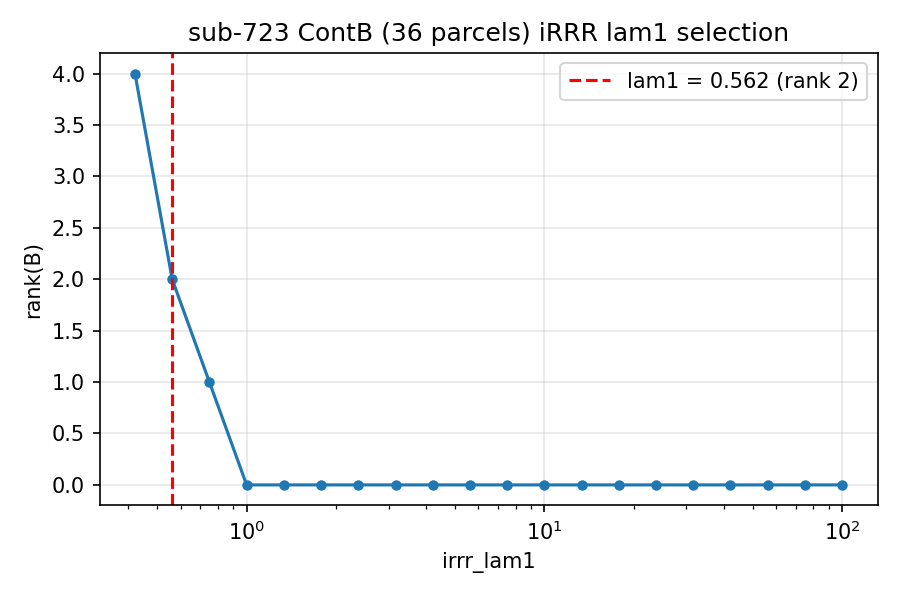

`sub-723/cont_EEG_cz_mnt-correct_pre2post18_3-stage_AR-iRRR-network_Hp/sub-723_ContC_iRRR_lam1_vs_rank.png` · 2026-11-06 11:18 · **new Adot**

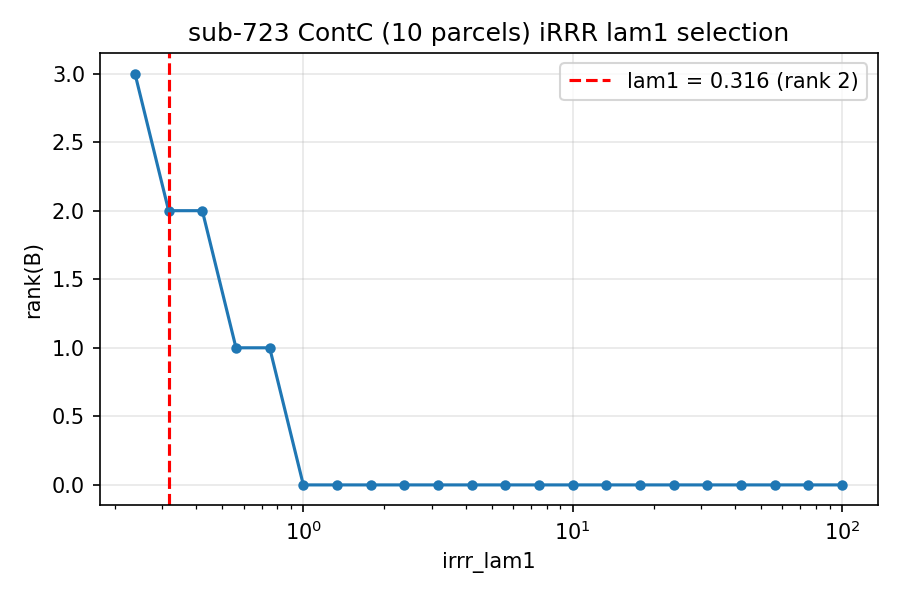

... 14 more; use n= or contains= (list_figs() shows all names)


In [9]:
show('contEEG_mnt-correct_network', 'sub-723', contains='hrf', n=3)

### GK_AR-iRRR_network — sub-723
**HRF basis:** Gaussian kernels (20), -2..18 s · **design:** mnt-correct onsets, iRRR per network · **noise model:** AR-iRRR · **script:** `run_model_gaussian-kernel_mnt-correct_network-based.py` · 17 figure(s)

`sub-723/mnt-correct_gauss_3-stage_AR-iRRR-network_Hp/sub-723_ContA_iRRR_lam1_vs_rank.png` · 2026-10-20 13:04 · **old Adot**

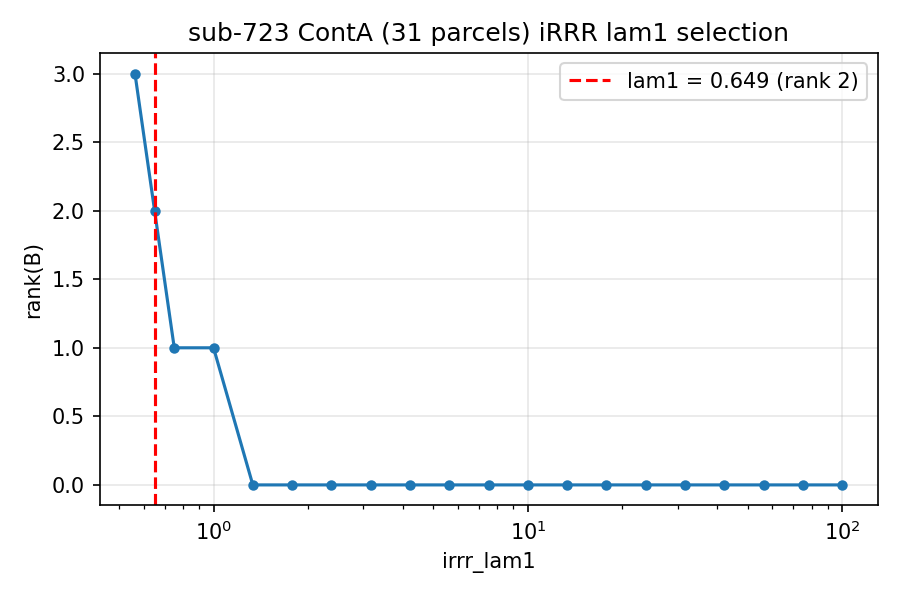

`sub-723/mnt-correct_gauss_3-stage_AR-iRRR-network_Hp/sub-723_ContB_iRRR_lam1_vs_rank.png` · 2026-10-20 13:05 · **old Adot**

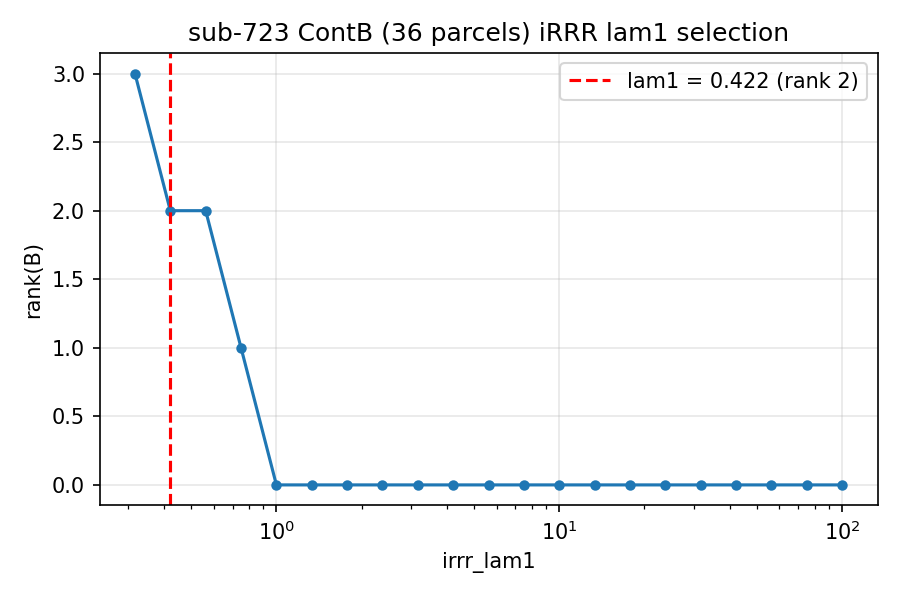

`sub-723/mnt-correct_gauss_3-stage_AR-iRRR-network_Hp/sub-723_ContC_iRRR_lam1_vs_rank.png` · 2026-10-20 13:05 · **old Adot**

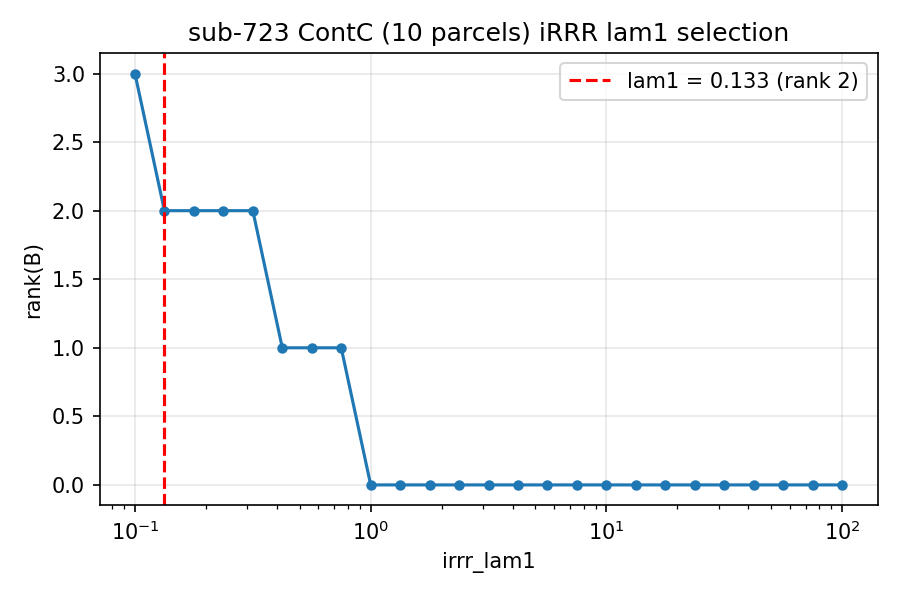

... 14 more; use n= or contains= (list_figs() shows all names)


In [10]:
show('GK_AR-iRRR_network', 'sub-723', contains='hrf', n=3)

### Bayes_GK — sub-723
**HRF basis:** Gaussian kernels (20), -2..18 s · **design:** mnt-correct onsets, single parcel, gradcpt1 · **noise model:** Bayesian AR (smoothness prior) · **script:** `Bayesian model/run_Bayes_image-space_gaussian-kernel_mnt-correct.py` · 4 figure(s)

`sub-723/Bayes-HRF-AR_mnt-correct_gauss_1-stage_gradcpt1_Hp/sub-723_DorsAttnB_PostC_2_RH_event3_fit.png` · 2026-11-02 13:10 · **old Adot**

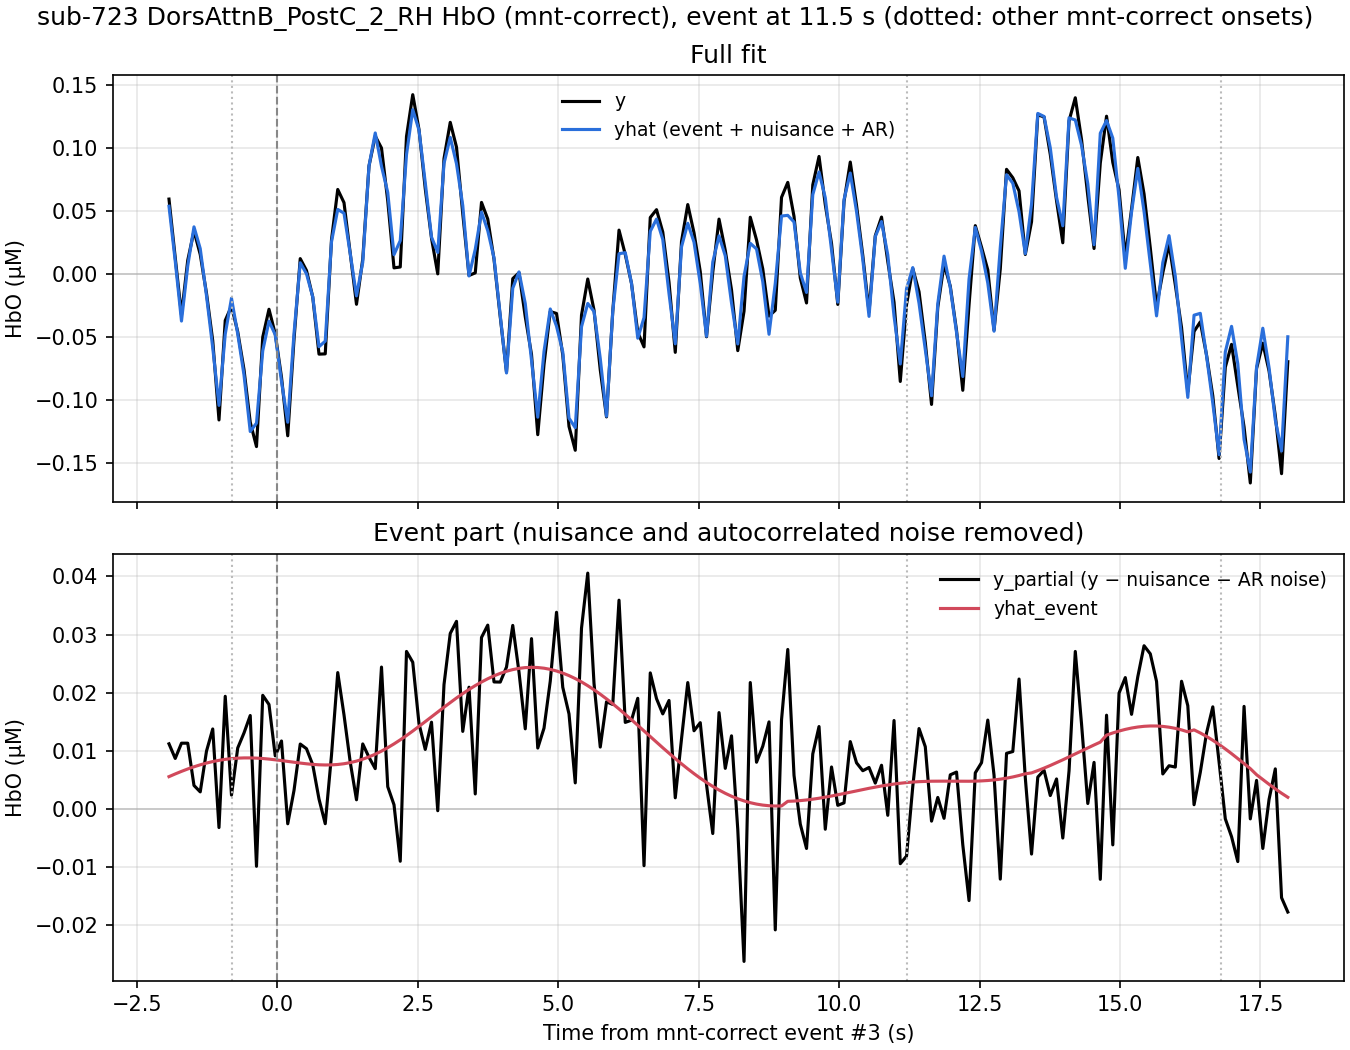

`sub-723/Bayes-HRF-AR_mnt-correct_gauss_1-stage_gradcpt1_Hp/sub-723_DorsAttnB_PostC_2_RH_posterior.png` · 2026-11-02 13:10 · **old Adot**

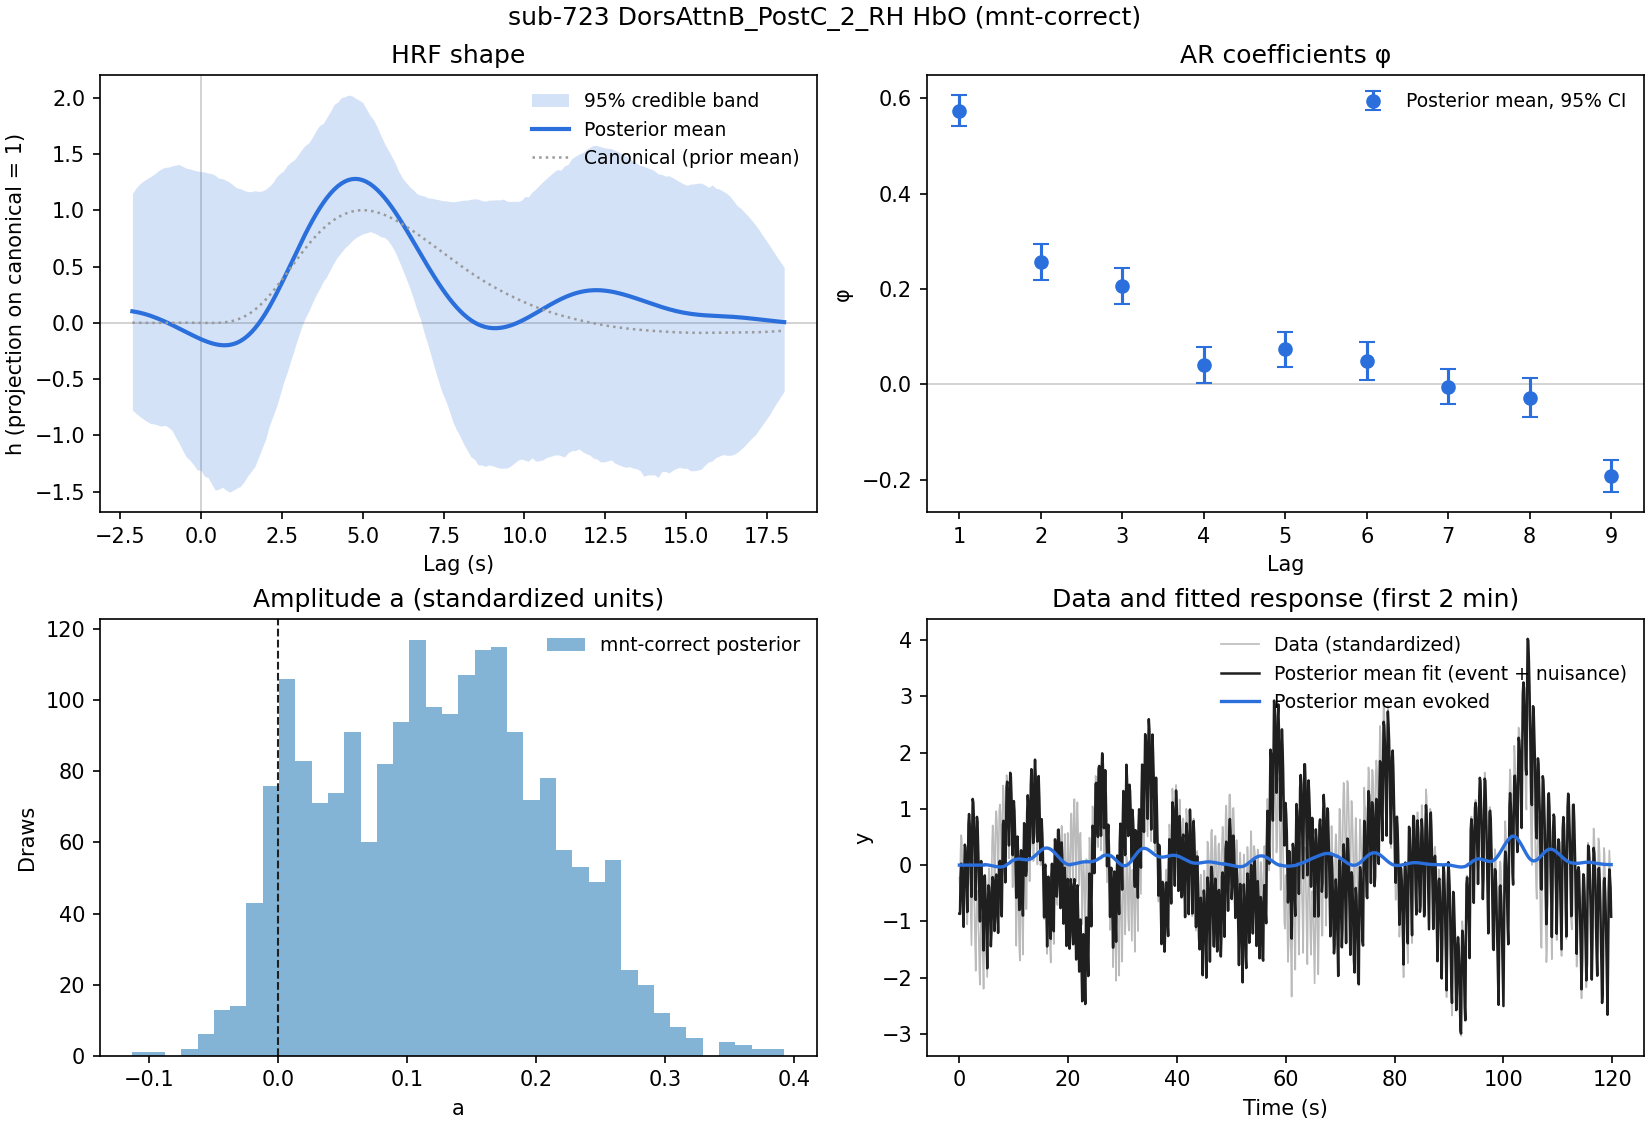

... 2 more; use n= or contains= (list_figs() shows all names)


In [11]:
show('Bayes_GK', 'sub-723', n=2)

### cmp_mnt-correct_4-design — group
**HRF basis:** B-spline + GK · **design:** GK vs EEG-informed GK vs contEEG designs · **noise model:** AR-IRLS · **script:** `summary notebook` · 3 figure(s)

`group/mnt-correct_4-design_cmp/summary_nb/group_hrf_12_networks_GK_vs_EEG-informed_parts.png` · 2026-11-03 16:41 · **old Adot**

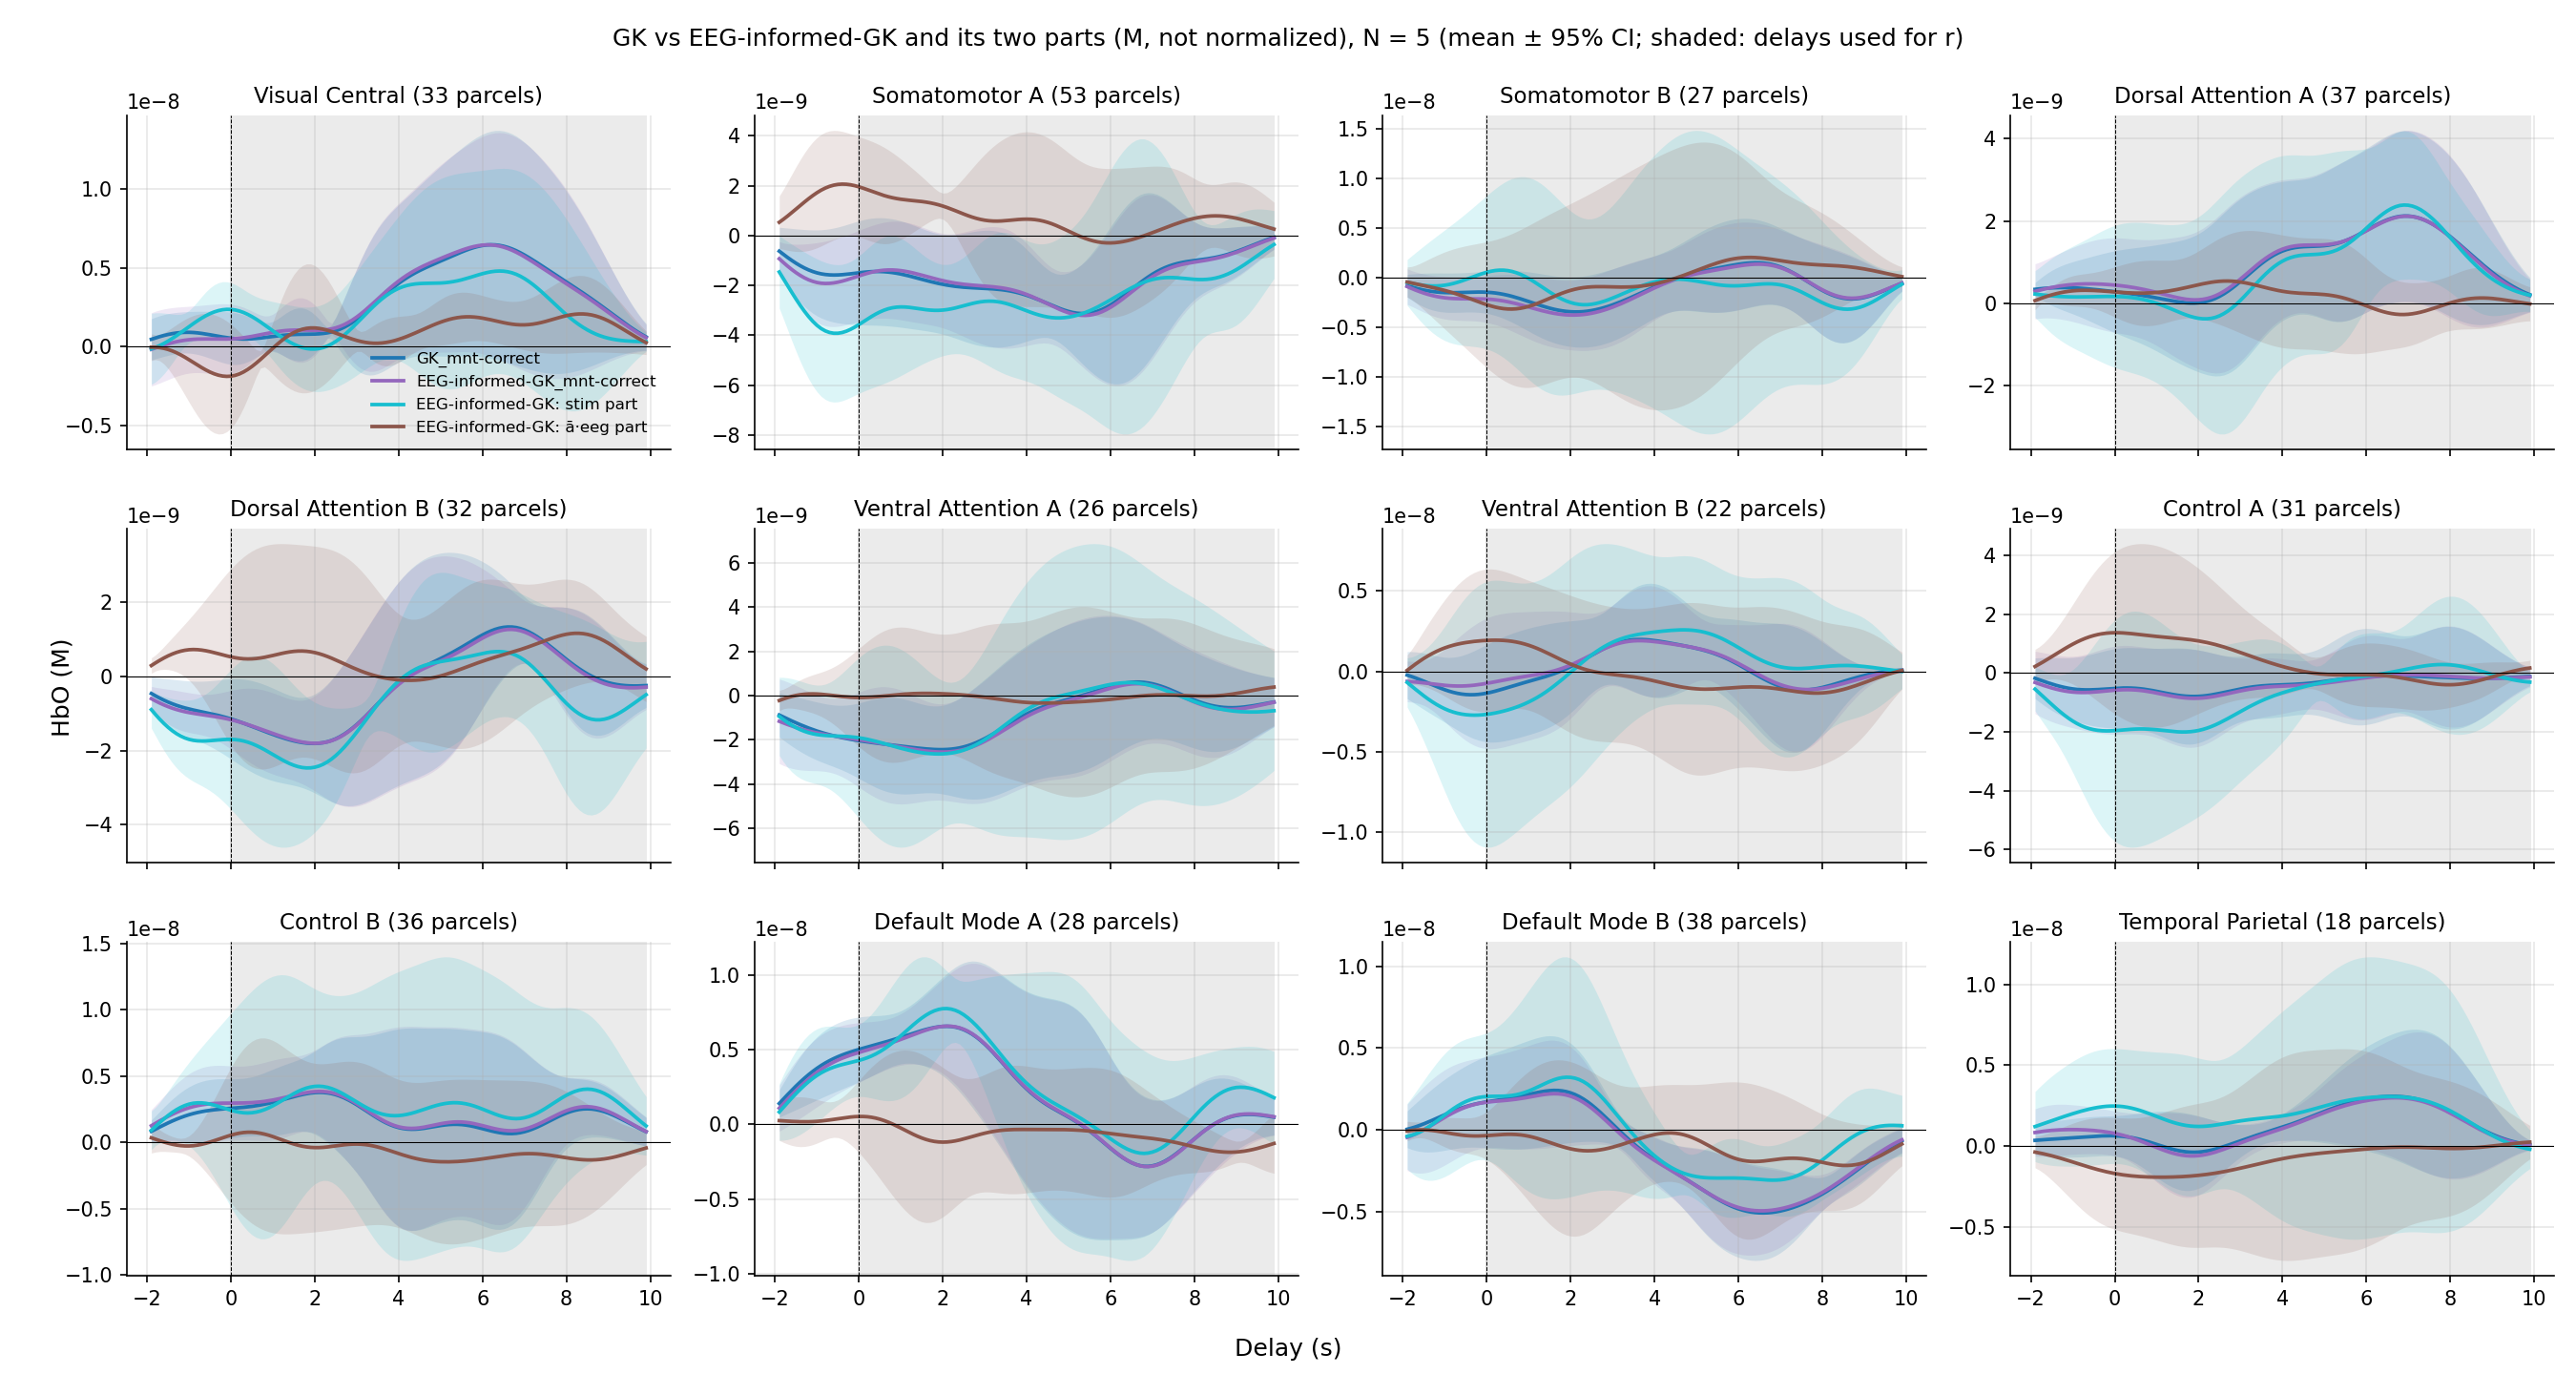

`group/mnt-correct_4-design_cmp/summary_nb/group_hrf_12_networks_norm.png` · 2026-11-03 16:41 · **old Adot**

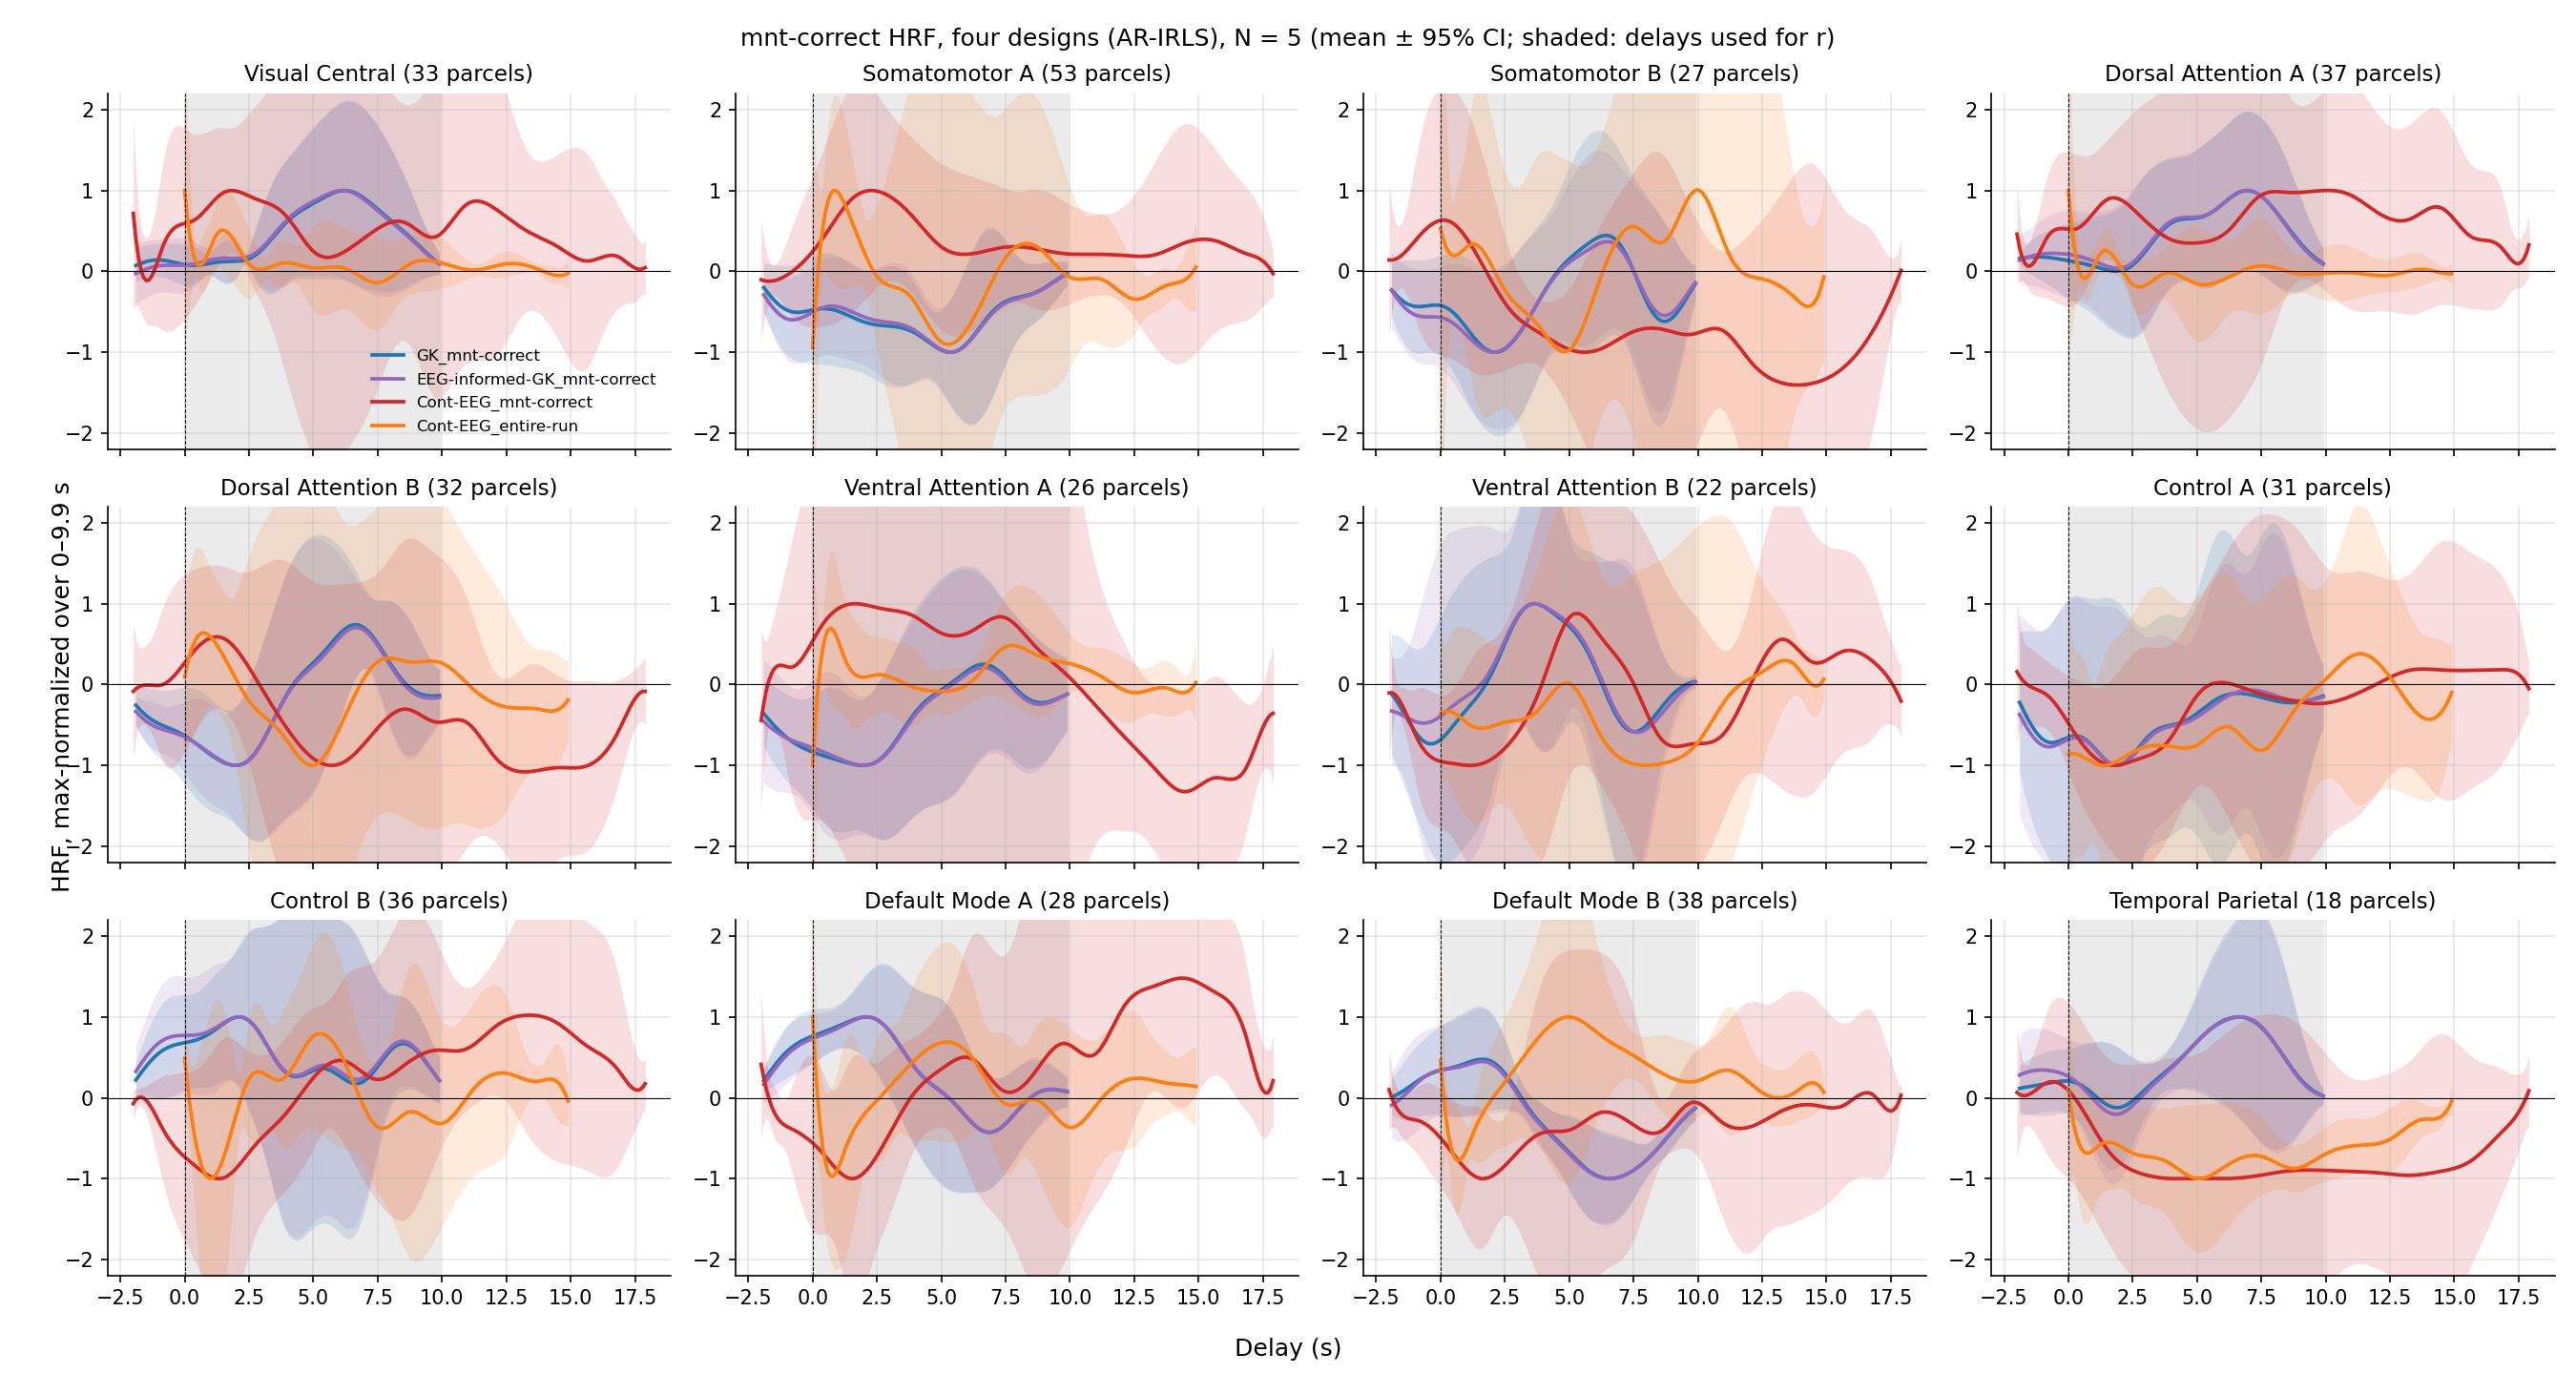

`group/mnt-correct_4-design_cmp/summary_nb/hrf_corr_matrix.png` · 2026-11-03 16:41 · **old Adot**

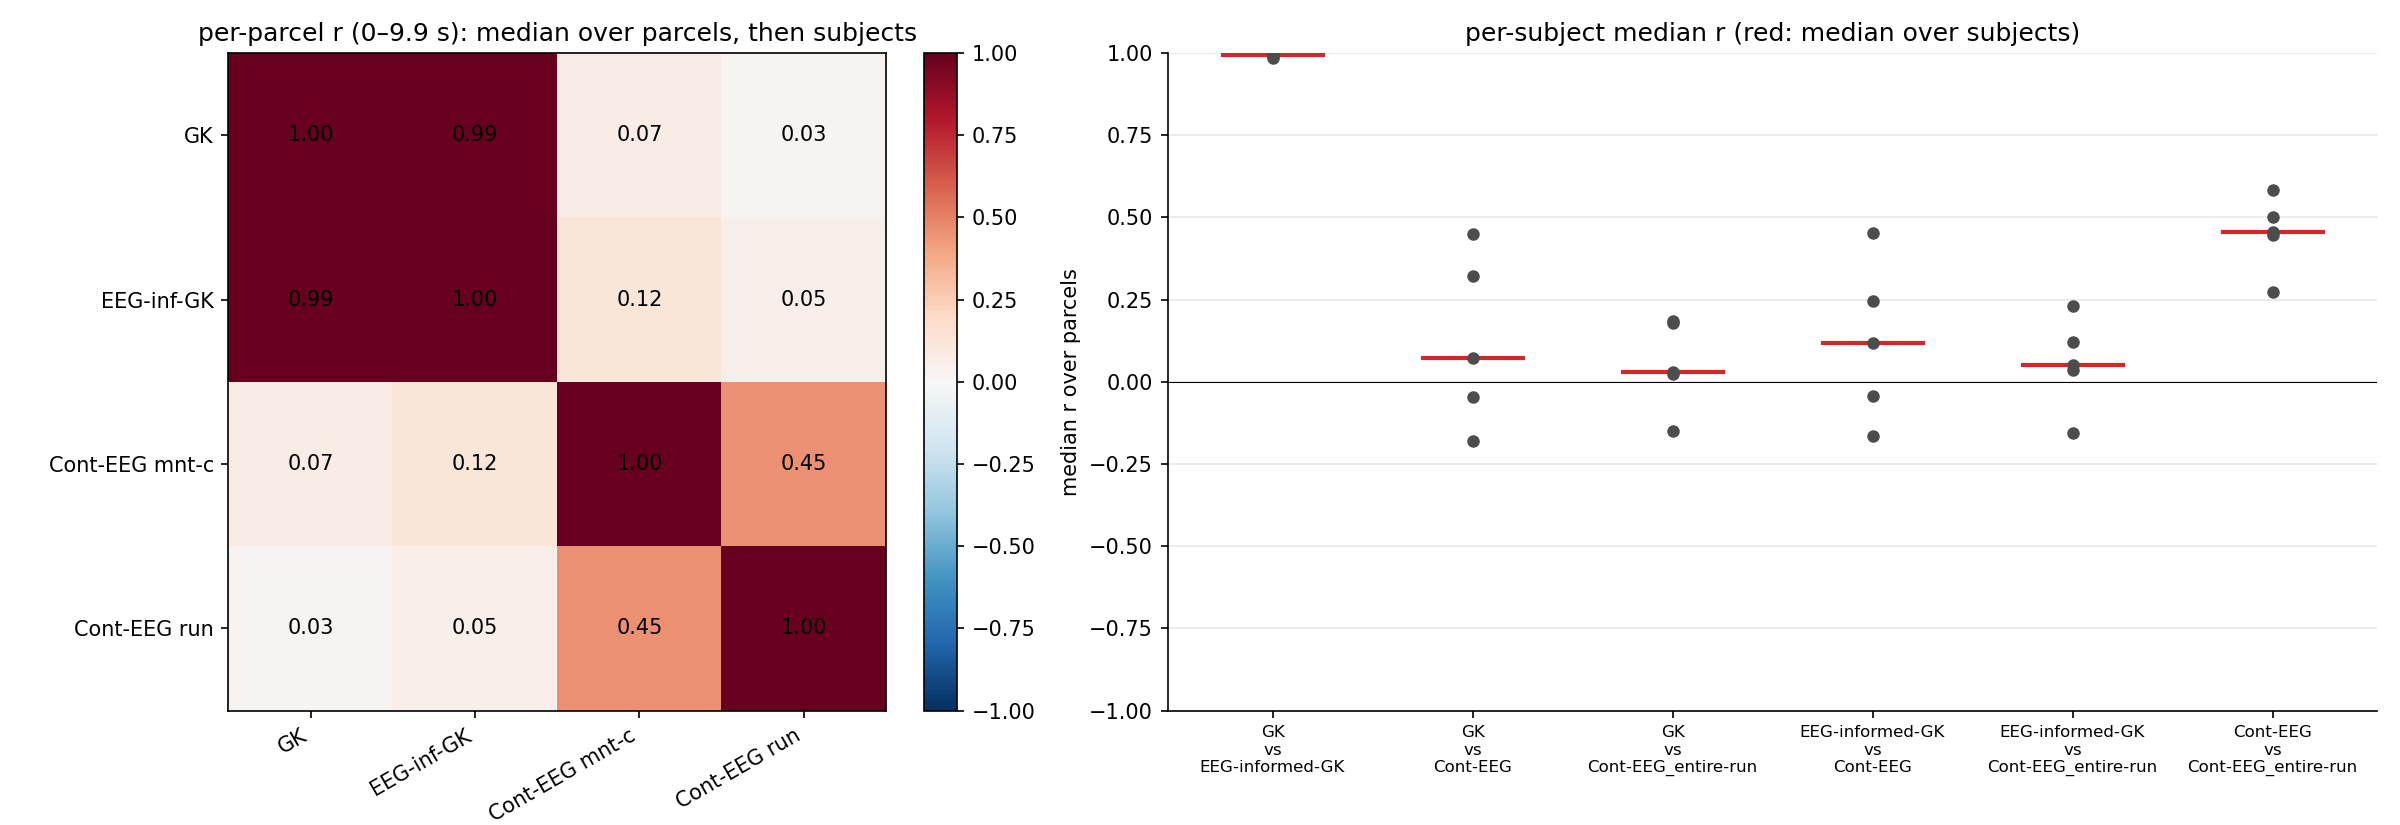

In [12]:
show('cmp_mnt-correct_4-design', 'group')